In [1]:
import asyncio
from deriv_api import DerivAPI
import pandas as pd
import numpy as np

# --- CONFIGURACIÓN V1.3 ---
ACTIVO = 'R_75'
INTERVALO = 900  # 15 Minutos
CANTIDAD = 5000 

async def motor_principal():
    print("🚀 Iniciando Motor V1.3 (Calculando RSI y TODOS los sensores)...")
    api = DerivAPI(app_id=1089)
    
    try:
        print("📡 Descargando datos...")
        response = await api.ticks_history({
            'ticks_history': ACTIVO, 'style': 'candles',
            'granularity': INTERVALO, 'count': CANTIDAD, 'end': 'latest'
        })
        
        df = pd.DataFrame(response['candles'])
        df['datetime'] = pd.to_datetime(df['epoch'], unit='s')
        df.set_index('datetime', inplace=True)
        df.drop(columns=['epoch'], inplace=True)
        
        # --- NUEVO SENSOR: RSI (14) ---
        delta = df['close'].diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
        rs = gain / loss
        df['RSI'] = 100 - (100 / (1 + rs))
        
        # --- SENSORES DE ESTRUCTURA E IMBALANCES ---
        n = 4  # Manteniendo tu configuración calibrada
        df['Pico'] = df['high'] == df['high'].rolling(window=(2*n)+1, center=True).max()
        df['Valle'] = df['low'] == df['low'].rolling(window=(2*n)+1, center=True).min()
        
        # EL PARCHE: Ambos FVGs están presentes
        df['FVG_Alcista'] = df['low'] > df['high'].shift(2)
        df['FVG_Bajista'] = df['high'] < df['low'].shift(2)
        
        print("\n✅ MOTOR V1.3 LISTO. Matriz de datos completa.")
        return df

    except Exception as e:
        print(f"❌ Error: {e}")
    finally:
        await api.disconnect()  

datos = await motor_principal()

🚀 Iniciando Motor V1.3 (Calculando RSI y TODOS los sensores)...
📡 Descargando datos...

✅ MOTOR V1.3 LISTO. Matriz de datos completa.


In [3]:
import pandas as pd

print("⚖️ Ejecutando Juez V2.0 (Motor Híbrido SMC + IA 👁️)...")

ultimo_pico_precio = 0.0
indice_ultimo_pico = None
ultimo_valle_precio = 0.0
indice_ultimo_valle = None

zonas_alta_probabilidad = []
dataset_ml = [] # NUEVO: La mochila donde guardaremos los datos para Machine Learning

# --- Contadores COMPRAS ---
w_base_c = 0; l_base_c = 0       
w_fibo_c = 0; l_fibo_c = 0       
w_rsi_c = 0;  l_rsi_c = 0        
w_full_c = 0; l_full_c = 0       
w_ia_c = 0;   l_ia_c = 0 # Contadores IA Compras

# --- Contadores VENTAS ---
w_base_v = 0; l_base_v = 0       
w_fibo_v = 0; l_fibo_v = 0       
w_rsi_v = 0;  l_rsi_v = 0        
w_full_v = 0; l_full_v = 0       
w_ia_v = 0;   l_ia_v = 0 # Contadores IA Ventas

for fecha, vela in datos.iterrows():
    
    # ==========================================
    # 🟢 LÓGICA DE COMPRAS (LONGS)
    # ==========================================
    if vela['Pico'] == True:
        ultimo_pico_precio = vela['high']
        indice_ultimo_pico = fecha
        
    elif ultimo_pico_precio > 0 and vela['close'] > ultimo_pico_precio:
        rango_impulso = datos.loc[indice_ultimo_pico : fecha]
        fecha_ob = rango_impulso['low'].idxmin()
        vela_ob = datos.loc[fecha_ob]
        
        if datos.loc[fecha_ob : fecha].head(5)['FVG_Alcista'].any():
            nivel_50 = vela_ob['low'] + ((ultimo_pico_precio - vela_ob['low']) * 0.5)
            es_discount = vela_ob['high'] <= nivel_50
            
            valles_previos = datos[datos['Valle'] == True].loc[:fecha_ob].tail(2)
            tiene_divergencia = False
            fecha_previo = None
            rsi_previo = vela_ob['RSI'] # Valor por defecto
            
            if len(valles_previos) > 1:
                valle_a = valles_previos.iloc[-2] 
                fecha_previo = valles_previos.index[-2]
                rsi_previo = valle_a['RSI']
                if vela_ob['low'] < valle_a['low'] and vela_ob['RSI'] > valle_a['RSI']:
                    tiene_divergencia = True

            # --- 1. MEDICIÓN GEOMÉTRICA EN TIEMPO REAL ---
            velas_impulso = datos.index.get_loc(fecha) - datos.index.get_loc(fecha_ob)
            tamano_ob = vela_ob['high'] - vela_ob['low']
            cuerpo_bos = abs(vela['close'] - vela['open'])
            profundidad = ultimo_pico_precio - vela_ob['low']
            delta_rsi = abs(vela_ob['RSI'] - rsi_previo)

            # --- 2. FILTRO DE INTELIGENCIA ARTIFICIAL ---
            es_ia_ganadora = False
            if cuerpo_bos <= 252.63:
                if 156.10 < tamano_ob <= 173.55:
                    es_ia_ganadora = True
            else:
                if delta_rsi <= 22.24 and profundidad > 502.71:
                    es_ia_ganadora = True

            # --- 3. ETIQUETADO ---
            etiqueta = "⭐"
            if es_discount: etiqueta += "F"
            if tiene_divergencia: etiqueta += "R"
            
            etiqueta_base = etiqueta # Guardamos la etiqueta sin Ojo para los contadores
            if es_ia_ganadora:
                etiqueta += " 👁️"
            
            precio_entrada = vela_ob['high']
            sl = vela_ob['low']
            tp = precio_entrada + ((precio_entrada - sl) * 2)
            
            posicion_rompimiento = datos.index.get_loc(fecha)
            resultado = 'Pendiente'
            fecha_entrada_real = None
            
            if posicion_rompimiento + 1 < len(datos):
                futuro = datos.iloc[posicion_rompimiento + 1 :]
                velas_entrada = futuro[futuro['low'] <= precio_entrada]
                
                if not velas_entrada.empty:
                    fecha_entrada_real = velas_entrada.index[0]
                    futuro_post = datos.loc[fecha_entrada_real:]
                    for f_s, v_s in futuro_post.iterrows():
                        if v_s['low'] <= sl: 
                            resultado = 'Loss'; break
                        elif v_s['high'] >= tp: 
                            resultado = 'Win'; break
                            
            if resultado == 'Win':
                if etiqueta_base == "⭐": w_base_c += 1
                elif etiqueta_base == "⭐F": w_fibo_c += 1
                elif etiqueta_base == "⭐R": w_rsi_c += 1
                elif etiqueta_base == "⭐FR": w_full_c += 1
                if es_ia_ganadora: w_ia_c += 1
            elif resultado == 'Loss':
                if etiqueta_base == "⭐": l_base_c += 1
                elif etiqueta_base == "⭐F": l_fibo_c += 1
                elif etiqueta_base == "⭐R": l_rsi_c += 1
                elif etiqueta_base == "⭐FR": l_full_c += 1
                if es_ia_ganadora: l_ia_c += 1

            # --- EXTRACCIÓN DE CARACTERÍSTICAS PARA ML (COMPRAS) ---
            if resultado in ['Win', 'Loss']:
                target = 1 if resultado == 'Win' else 0
                dataset_ml.append({
                    'Tipo': 1, # 1 para compras
                    'Velas_Impulso': velas_impulso,
                    'Tamano_OB': tamano_ob,
                    'Cuerpo_BOS': cuerpo_bos,
                    'Profundidad_Pts': profundidad,
                    'Delta_RSI': delta_rsi,
                    'Target': target
                })

            zonas_alta_probabilidad.append({
                'Tipo': 'Compra', 'Fecha_OB': fecha_ob, 'Fecha_Rompimiento': fecha, 'Fecha_Prev': fecha_previo,
                'OB_High': vela_ob['high'], 'OB_Low': vela_ob['low'], 'RSI_OB': vela_ob['RSI'], 
                'RSI_Prev': valle_a['RSI'] if tiene_divergencia else None, 'Resultado': resultado, 
                'Estrellas': etiqueta, 'Divergencia': tiene_divergencia, 'Fecha_Entrada': fecha_entrada_real 
            })
        ultimo_pico_precio = 0.0

    # ==========================================
    # 🔴 LÓGICA DE VENTAS (SHORTS)
    # ==========================================
    if vela['Valle'] == True:
        ultimo_valle_precio = vela['low']
        indice_ultimo_valle = fecha
        
    elif ultimo_valle_precio > 0 and vela['close'] < ultimo_valle_precio:
        rango_impulso = datos.loc[indice_ultimo_valle : fecha]
        fecha_ob = rango_impulso['high'].idxmax()
        vela_ob = datos.loc[fecha_ob]
        
        if datos.loc[fecha_ob : fecha].head(5)['FVG_Bajista'].any():
            nivel_50 = ultimo_valle_precio + ((vela_ob['high'] - ultimo_valle_precio) * 0.5)
            es_premium = vela_ob['low'] >= nivel_50
            
            picos_previos = datos[datos['Pico'] == True].loc[:fecha_ob].tail(2)
            tiene_divergencia = False
            fecha_previo = None
            rsi_previo = vela_ob['RSI'] # Valor por defecto
            
            if len(picos_previos) > 1:
                pico_a = picos_previos.iloc[-2] 
                fecha_previo = picos_previos.index[-2]
                rsi_previo = pico_a['RSI']
                if vela_ob['high'] > pico_a['high'] and vela_ob['RSI'] < pico_a['RSI']:
                    tiene_divergencia = True

            # --- 1. MEDICIÓN GEOMÉTRICA EN TIEMPO REAL ---
            velas_impulso = datos.index.get_loc(fecha) - datos.index.get_loc(fecha_ob)
            tamano_ob = vela_ob['high'] - vela_ob['low']
            cuerpo_bos = abs(vela['close'] - vela['open'])
            profundidad = vela_ob['high'] - ultimo_valle_precio
            delta_rsi = abs(vela_ob['RSI'] - rsi_previo)

            # --- 2. FILTRO DE INTELIGENCIA ARTIFICIAL ---
            es_ia_ganadora = False
            if profundidad <= 599.56:
                if velas_impulso <= 3.50 and tamano_ob <= 157.43:
                    es_ia_ganadora = True
            else:
                if delta_rsi <= 9.87:
                    es_ia_ganadora = True

            # --- 3. ETIQUETADO ---
            etiqueta = "⭐"
            if es_premium: etiqueta += "F"
            if tiene_divergencia: etiqueta += "R"
            
            etiqueta_base = etiqueta
            if es_ia_ganadora:
                etiqueta += " 👁️"
            
            precio_entrada = vela_ob['low']  
            sl = vela_ob['high']             
            tp = precio_entrada - ((sl - precio_entrada) * 2) 
            
            posicion_rompimiento = datos.index.get_loc(fecha)
            resultado = 'Pendiente'
            fecha_entrada_real = None
            
            if posicion_rompimiento + 1 < len(datos):
                futuro = datos.iloc[posicion_rompimiento + 1 :]
                velas_entrada = futuro[futuro['high'] >= precio_entrada]
                
                if not velas_entrada.empty:
                    fecha_entrada_real = velas_entrada.index[0]
                    futuro_post = datos.loc[fecha_entrada_real:]
                    for f_s, v_s in futuro_post.iterrows():
                        if v_s['high'] >= sl:  
                            resultado = 'Loss'; break
                        elif v_s['low'] <= tp: 
                            resultado = 'Win'; break
                            
            if resultado == 'Win':
                if etiqueta_base == "⭐": w_base_v += 1
                elif etiqueta_base == "⭐F": w_fibo_v += 1
                elif etiqueta_base == "⭐R": w_rsi_v += 1
                elif etiqueta_base == "⭐FR": w_full_v += 1
                if es_ia_ganadora: w_ia_v += 1
            elif resultado == 'Loss':
                if etiqueta_base == "⭐": l_base_v += 1
                elif etiqueta_base == "⭐F": l_fibo_v += 1
                elif etiqueta_base == "⭐R": l_rsi_v += 1
                elif etiqueta_base == "⭐FR": l_full_v += 1
                if es_ia_ganadora: l_ia_v += 1

            # --- EXTRACCIÓN DE CARACTERÍSTICAS PARA ML (VENTAS) ---
            if resultado in ['Win', 'Loss']:
                target = 1 if resultado == 'Win' else 0
                dataset_ml.append({
                    'Tipo': 0, # 0 para ventas
                    'Velas_Impulso': velas_impulso,
                    'Tamano_OB': tamano_ob,
                    'Cuerpo_BOS': cuerpo_bos,
                    'Profundidad_Pts': profundidad,
                    'Delta_RSI': delta_rsi,
                    'Target': target
                })

            zonas_alta_probabilidad.append({
                'Tipo': 'Venta', 'Fecha_OB': fecha_ob, 'Fecha_Rompimiento': fecha, 'Fecha_Prev': fecha_previo,
                'OB_High': vela_ob['high'], 'OB_Low': vela_ob['low'], 'RSI_OB': vela_ob['RSI'], 
                'RSI_Prev': pico_a['RSI'] if tiene_divergencia else None, 'Resultado': resultado, 
                'Estrellas': etiqueta, 'Divergencia': tiene_divergencia, 'Fecha_Entrada': fecha_entrada_real 
            })
        ultimo_valle_precio = 0.0

df_zonas_perfectas = pd.DataFrame(zonas_alta_probabilidad)

# --- GUARDAR DATASET PARA MACHINE LEARNING ---
df_ml = pd.DataFrame(dataset_ml)
df_ml.to_csv('dataset_sintetico_ml.csv', index=False)
print(f"\n💾 ¡DATASET GENERADO! Se guardaron {len(df_ml)} operaciones matemáticas en 'dataset_sintetico_ml.csv'")

# --- CÁLCULOS COMPRAS ---
t_base_c = w_base_c + l_base_c; wr_base_c = (w_base_c / t_base_c * 100) if t_base_c > 0 else 0
t_fibo_c = w_fibo_c + l_fibo_c; wr_fibo_c = (w_fibo_c / t_fibo_c * 100) if t_fibo_c > 0 else 0
t_rsi_c = w_rsi_c + l_rsi_c;    wr_rsi_c = (w_rsi_c / t_rsi_c * 100) if t_rsi_c > 0 else 0
t_full_c = w_full_c + l_full_c; wr_full_c = (w_full_c / t_full_c * 100) if t_full_c > 0 else 0

w_tot_c = w_base_c + w_fibo_c + w_rsi_c + w_full_c
l_tot_c = l_base_c + l_fibo_c + l_rsi_c + l_full_c
t_tot_c = w_tot_c + l_tot_c
wr_tot_c = (w_tot_c / t_tot_c * 100) if t_tot_c > 0 else 0
t_ia_c = w_ia_c + l_ia_c; wr_ia_c = (w_ia_c / t_ia_c * 100) if t_ia_c > 0 else 0

# --- CÁLCULOS VENTAS ---
t_base_v = w_base_v + l_base_v; wr_base_v = (w_base_v / t_base_v * 100) if t_base_v > 0 else 0
t_fibo_v = w_fibo_v + l_fibo_v; wr_fibo_v = (w_fibo_v / t_fibo_v * 100) if t_fibo_v > 0 else 0
t_rsi_v = w_rsi_v + l_rsi_v;    wr_rsi_v = (w_rsi_v / t_rsi_v * 100) if t_rsi_v > 0 else 0
t_full_v = w_full_v + l_full_v; wr_full_v = (w_full_v / t_full_v * 100) if t_full_v > 0 else 0

w_tot_v = w_base_v + w_fibo_v + w_rsi_v + w_full_v
l_tot_v = l_base_v + l_fibo_v + l_rsi_v + l_full_v
t_tot_v = w_tot_v + l_tot_v
wr_tot_v = (w_tot_v / t_tot_v * 100) if t_tot_v > 0 else 0
t_ia_v = w_ia_v + l_ia_v; wr_ia_v = (w_ia_v / t_ia_v * 100) if t_ia_v > 0 else 0

# --- CÁLCULOS GLOBALES ---
w_global = w_tot_c + w_tot_v
l_global = l_tot_c + l_tot_v
t_global = w_global + l_global
wr_global = (w_global / t_global * 100) if t_global > 0 else 0
t_ia_global = t_ia_c + t_ia_v
w_ia_global = w_ia_c + w_ia_v
wr_ia_global = (w_ia_global / t_ia_global * 100) if t_ia_global > 0 else 0

print("\n==================================================")
print("🟢 REPORTE DE COMPRAS (LONGS)")
print("==================================================")
print(f"Total Ops: {t_tot_c} | Winrate: {wr_tot_c:.2f}% ({w_tot_c}W / {l_tot_c}L)")
print(f" [⭐] BASE      | Ops: {t_base_c:2} | Efectividad: {wr_base_c:5.2f}% ({w_base_c}W/{l_base_c}L)")
print(f" [⭐F] FIBO     | Ops: {t_fibo_c:2} | Efectividad: {wr_fibo_c:5.2f}% ({w_fibo_c}W/{l_fibo_c}L)")
print(f" [⭐R] RSI      | Ops: {t_rsi_c:2} | Efectividad: {wr_rsi_c:5.2f}% ({w_rsi_c}W/{l_rsi_c}L)")
print(f" [⭐FR] FULL    | Ops: {t_full_c:2} | Efectividad: {wr_full_c:5.2f}% ({w_full_c}W/{l_full_c}L)")
print(f"\n 👁️ SEÑALES IA | Ops: {t_ia_c:2} | Efectividad: {wr_ia_c:5.2f}% ({w_ia_c}W/{l_ia_c}L)")

print("\n==================================================")
print("🔴 REPORTE DE VENTAS (SHORTS)")
print("==================================================")
print(f"Total Ops: {t_tot_v} | Winrate: {wr_tot_v:.2f}% ({w_tot_v}W / {l_tot_v}L)")
print(f" [⭐] BASE      | Ops: {t_base_v:2} | Efectividad: {wr_base_v:5.2f}% ({w_base_v}W/{l_base_v}L)")
print(f" [⭐F] FIBO     | Ops: {t_fibo_v:2} | Efectividad: {wr_fibo_v:5.2f}% ({w_fibo_v}W/{l_fibo_v}L)")
print(f" [⭐R] RSI      | Ops: {t_rsi_v:2} | Efectividad: {wr_rsi_v:5.2f}% ({w_rsi_v}W/{l_rsi_v}L)")
print(f" [⭐FR] FULL    | Ops: {t_full_v:2} | Efectividad: {wr_full_v:5.2f}% ({w_full_v}W/{l_full_v}L)")
print(f"\n 👁️ SEÑALES IA | Ops: {t_ia_v:2} | Efectividad: {wr_ia_v:5.2f}% ({w_ia_v}W/{l_ia_v}L)")

print("\n==================================================")
print(f"🏆 RESUMEN GLOBAL UNIFICADO: {wr_global:.2f}% | Ops Totales: {t_global}")
print(f"🤖 RESUMEN GLOBAL IA (OJO) : {wr_ia_global:.2f}% | Ops Totales: {t_ia_global}")
print("==================================================")

⚖️ Ejecutando Juez V2.0 (Motor Híbrido SMC + IA 👁️)...

💾 ¡DATASET GENERADO! Se guardaron 119 operaciones matemáticas en 'dataset_sintetico_ml.csv'

🟢 REPORTE DE COMPRAS (LONGS)
Total Ops: 60 | Winrate: 40.00% (24W / 36L)
 [⭐] BASE      | Ops: 22 | Efectividad: 45.45% (10W/12L)
 [⭐F] FIBO     | Ops: 35 | Efectividad: 40.00% (14W/21L)
 [⭐R] RSI      | Ops:  0 | Efectividad:  0.00% (0W/0L)
 [⭐FR] FULL    | Ops:  3 | Efectividad:  0.00% (0W/3L)

 👁️ SEÑALES IA | Ops: 25 | Efectividad: 40.00% (10W/15L)

🔴 REPORTE DE VENTAS (SHORTS)
Total Ops: 59 | Winrate: 35.59% (21W / 38L)
 [⭐] BASE      | Ops: 18 | Efectividad: 38.89% (7W/11L)
 [⭐F] FIBO     | Ops: 36 | Efectividad: 30.56% (11W/25L)
 [⭐R] RSI      | Ops:  2 | Efectividad: 100.00% (2W/0L)
 [⭐FR] FULL    | Ops:  3 | Efectividad: 33.33% (1W/2L)

 👁️ SEÑALES IA | Ops: 19 | Efectividad: 26.32% (5W/14L)

🏆 RESUMEN GLOBAL UNIFICADO: 37.82% | Ops Totales: 119
🤖 RESUMEN GLOBAL IA (OJO) : 34.09% | Ops Totales: 44


In [4]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

print("🎨 Generando HMI V2.0 (Gráfico Híbrido SMC + IA)...")

velas_a_graficar = 3000 
df_plot = datos.tail(velas_a_graficar)
fecha_inicio_plot = df_plot.index[0]
ultimo_tiempo = df_plot.index[-1]

# Filtramos usando el nuevo dataframe
zonas_v20 = df_zonas_perfectas[df_zonas_perfectas['Fecha_OB'] >= fecha_inicio_plot]

fig = make_subplots(rows=2, cols=1, shared_xaxes=True, 
                    vertical_spacing=0.05, row_heights=[0.75, 0.25], 
                    subplot_titles=("Gráfico Maestro V2.0 (SMC + Filtro IA 👁️)", "RSI Momentum"))

fig.add_trace(go.Candlestick(
    x=df_plot.index, open=df_plot['open'], high=df_plot['high'],
    low=df_plot['low'], close=df_plot['close'], name='V75'
), row=1, col=1)

for _, zona in zonas_v20.iterrows():
    top_y = zona['OB_High']
    bottom_y = zona['OB_Low']
    start_x = zona['Fecha_OB']
    
    if pd.notna(zona.get('Fecha_Entrada')): end_x = zona['Fecha_Entrada']
    else: end_x = ultimo_tiempo 
        
    resultado = zona.get('Resultado', 'Pendiente')
    
    # Colores: Verde (Win), Amarillo (Loss), Azul (Pendiente)
    if resultado == 'Win': color = 'rgba(0, 255, 0, 0.3)'
    elif resultado == 'Loss': color = 'rgba(255, 255, 0, 0.3)'
    else: color = 'rgba(0, 150, 255, 0.4)'
        
    fig.add_shape(
        type="rect", x0=start_x, y0=bottom_y, x1=end_x, y1=top_y,
        fillcolor=color, line=dict(color=color.replace('0.3', '0.8').replace('0.4', '0.8'), width=1),
        layer="below", row=1, col=1
    )
    
    # Dibujar líneas de divergencia correctamente (Compras vs Ventas)
    if zona['Divergencia'] == True:
        if zona['Tipo'] == 'Compra':
            y_precio_prev = datos.loc[zona['Fecha_Prev']]['low']
            y_precio_ob = zona['OB_Low']
        else:
            y_precio_prev = datos.loc[zona['Fecha_Prev']]['high']
            y_precio_ob = zona['OB_High']
            
        fig.add_trace(go.Scatter(
            x=[zona['Fecha_Prev'], zona['Fecha_OB']],
            y=[y_precio_prev, y_precio_ob],
            mode='lines', line=dict(color='red', width=2, dash='dot'), showlegend=False
        ), row=1, col=1)
        
        fig.add_trace(go.Scatter(
            x=[zona['Fecha_Prev'], zona['Fecha_OB']],
            y=[zona['RSI_Prev'], zona['RSI_OB']],
            mode='lines', line=dict(color='lime', width=2, dash='solid'), showlegend=False
        ), row=2, col=1)

    # --- NUEVO: ESTILO VIP PARA OPERACIONES DE INTELIGENCIA ARTIFICIAL ---
    es_ia = "👁️" in zona['Estrellas']
    color_texto = "cyan" if es_ia else "white"
    tamano_texto = 16 if es_ia else 13
    
    texto_etiqueta = f"{'▲' if zona['Tipo'] == 'Compra' else '▼'} {zona['Estrellas']}"
    
    fig.add_annotation(
        x=zona['Fecha_OB'], y=zona['OB_High'] if zona['Tipo'] == 'Compra' else zona['OB_Low'],
        text=texto_etiqueta, showarrow=False, 
        yshift=18 if zona['Tipo'] == 'Compra' else -18, # Ligeramente más separado para el texto grande
        font=dict(size=tamano_texto, color=color_texto), row=1, col=1
    )

fig.add_trace(go.Scatter(x=df_plot.index, y=df_plot['RSI'], line=dict(color='orange', width=1.5), name='RSI'), row=2, col=1)
fig.add_hline(y=70, line_dash="dot", line_color="red", row=2, col=1)
fig.add_hline(y=30, line_dash="dot", line_color="green", row=2, col=1)

fig.update_layout(
    title='HMI Súper Indicador V2.0', template='plotly_dark', height=900,
    xaxis_rangeslider_visible=False, margin=dict(l=50, r=50, b=50, t=80)
)
fig.update_xaxes(matches='x')
fig.show()

🎨 Generando HMI V2.0 (Gráfico Híbrido SMC + IA)...


In [10]:
# Extraer datos de la zona de interés (7 de mayo de 2026)
inicio_auditoria = '2026-05-03 08:45:00'
fin_auditoria = '2026-05-03 21:30:00'
fragmento = datos.loc[inicio_auditoria : fin_auditoria]

# Guardar solo este fragmento para inspección detallada en Excel o VS Code
fragmento.to_csv('auditoria_OB_3.csv')
print("✅ Archivo 'auditoria_ob_7mayo.csv' generado. Revisa las columnas 'low', 'close' y 'Pico'.")

✅ Archivo 'auditoria_ob_7mayo.csv' generado. Revisa las columnas 'low', 'close' y 'Pico'.


📊 Iniciando Laboratorio Estadístico (Generando Mapas y Reporte de Texto)...

📋 DATOS DE CORRELACIÓN PARA EL CHAT

🟢 COMPRAS (Longs) - Correlación con el 'Target':
Target             1.0000
Cuerpo_BOS         0.2229
Profundidad_Pts    0.0670
Velas_Impulso     -0.0969
Delta_RSI         -0.1424
Tamano_OB         -0.2217

🔴 VENTAS (Shorts) - Correlación con el 'Target':
Target             1.0000
Profundidad_Pts    0.2317
Velas_Impulso      0.1325
Cuerpo_BOS         0.0434
Tamano_OB         -0.0041
Delta_RSI         -0.0934



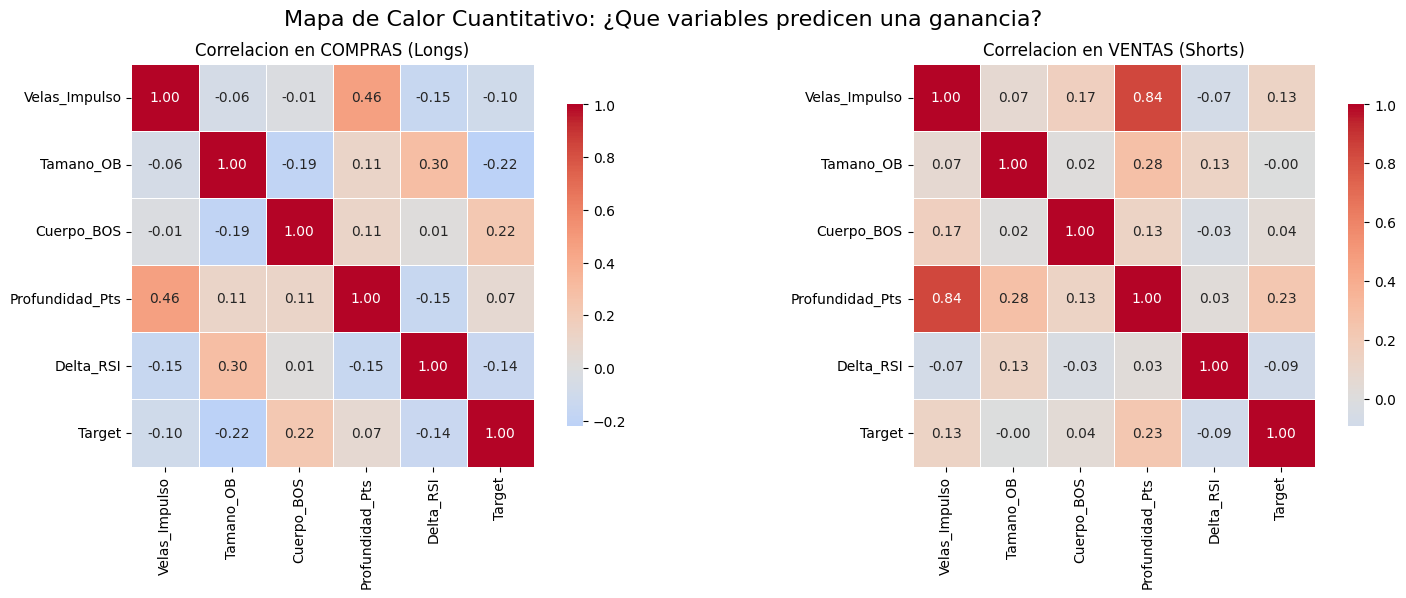

✅ Análisis completado con éxito.


In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print("📊 Iniciando Laboratorio Estadístico (Generando Mapas y Reporte de Texto)...")

# 1. Cargar la materia prima
df_ml = pd.read_csv('dataset_sintetico_ml.csv')

# 2. Separar Compras (Tipo 1) y Ventas (Tipo 0)
df_compras = df_ml[df_ml['Tipo'] == 1].drop(columns=['Tipo'])
df_ventas = df_ml[df_ml['Tipo'] == 0].drop(columns=['Tipo'])

# 3. Calcular las matrices de correlación de Pearson
corr_compras = df_compras.corr()
corr_ventas = df_ventas.corr()

# --- NUEVO: REPORTE EN TEXTO PARA EXPORTAR ---
print("\n" + "="*50)
print("📋 DATOS DE CORRELACIÓN PARA EL CHAT")
print("="*50)
print("\n🟢 COMPRAS (Longs) - Correlación con el 'Target':")
print(corr_compras['Target'].sort_values(ascending=False).round(4).to_string())

print("\n🔴 VENTAS (Shorts) - Correlación con el 'Target':")
print(corr_ventas['Target'].sort_values(ascending=False).round(4).to_string())
print("="*50 + "\n")

# 4. Configurar el lienzo visual (2 paneles - Sin emojis en los títulos gráficos)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Mapa de Calor Cuantitativo: ¿Que variables predicen una ganancia?', fontsize=16)

# Mapa de Calor - COMPRAS
sns.heatmap(corr_compras, annot=True, fmt=".2f", cmap="coolwarm", center=0, 
            square=True, linewidths=.5, cbar_kws={"shrink": .8}, ax=ax[0])
ax[0].set_title('Correlacion en COMPRAS (Longs)')

# Mapa de Calor - VENTAS
sns.heatmap(corr_ventas, annot=True, fmt=".2f", cmap="coolwarm", center=0, 
            square=True, linewidths=.5, cbar_kws={"shrink": .8}, ax=ax[1])
ax[1].set_title('Correlacion en VENTAS (Shorts)')

# Ajustar diseño y mostrar
plt.tight_layout()
plt.show()

print("✅ Análisis completado con éxito.")

In [15]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text

print("🧠 Encendiendo el Motor de Machine Learning (Árboles de Decisión)...")

# 1. Cargar el dataset que creamos en la Celda 2
df_ml = pd.read_csv('dataset_sintetico_ml.csv')

# 2. Separar datos de Compras y Ventas
df_compras = df_ml[df_ml['Tipo'] == 1].copy()
df_ventas = df_ml[df_ml['Tipo'] == 0].copy()

def entrenar_y_extraer_reglas(df, nombre_direccion):
    # Separar las características (X) del resultado final (y)
    X = df.drop(columns=['Tipo', 'Target'])
    y = df['Target']
    
    # Crear el modelo de IA (max_depth=3 para que las reglas sean simples y programables)
    modelo = DecisionTreeClassifier(max_depth=3, random_state=42, min_samples_leaf=5)
    
    # 💥 ENTRENAMIENTO: Aquí ocurren millones de cálculos matemáticos en 1 segundo
    modelo.fit(X, y)
    
    # Extraer el flujograma en formato de texto
    reglas = export_text(modelo, feature_names=list(X.columns))
    
    print("\n" + "="*50)
    print(f"🤖 LEYES MATEMÁTICAS DESCUBIERTAS PARA: {nombre_direccion}")
    print("="*50)
    print(reglas)
    print("📌 GUÍA DE LECTURA:")
    print("  -> 'class: 1' significa WIN (¡Esta es la regla que queremos operar!)")
    print("  -> 'class: 0' significa LOSS (El setup es basura, ignorarlo)")

# Ejecutar la IA para ambas direcciones
if not df_compras.empty:
    entrenar_y_extraer_reglas(df_compras, "COMPRAS (Longs)")
    
if not df_ventas.empty:
    entrenar_y_extraer_reglas(df_ventas, "VENTAS (Shorts)")

🧠 Encendiendo el Motor de Machine Learning (Árboles de Decisión)...

🤖 LEYES MATEMÁTICAS DESCUBIERTAS PARA: COMPRAS (Longs)
|--- Cuerpo_BOS <= 252.63
|   |--- Tamano_OB <= 173.55
|   |   |--- Tamano_OB <= 156.10
|   |   |   |--- class: 0
|   |   |--- Tamano_OB >  156.10
|   |   |   |--- class: 1
|   |--- Tamano_OB >  173.55
|   |   |--- Delta_RSI <= 8.07
|   |   |   |--- class: 0
|   |   |--- Delta_RSI >  8.07
|   |   |   |--- class: 0
|--- Cuerpo_BOS >  252.63
|   |--- Delta_RSI <= 22.24
|   |   |--- Profundidad_Pts <= 502.71
|   |   |   |--- class: 0
|   |   |--- Profundidad_Pts >  502.71
|   |   |   |--- class: 1
|   |--- Delta_RSI >  22.24
|   |   |--- class: 0

📌 GUÍA DE LECTURA:
  -> 'class: 1' significa WIN (¡Esta es la regla que queremos operar!)
  -> 'class: 0' significa LOSS (El setup es basura, ignorarlo)

🤖 LEYES MATEMÁTICAS DESCUBIERTAS PARA: VENTAS (Shorts)
|--- Profundidad_Pts <= 599.56
|   |--- Velas_Impulso <= 3.50
|   |   |--- Tamano_OB <= 157.43
|   |   |   |--- clas